<a href="https://colab.research.google.com/github/wafae36/projet7-vlm-compacts/blob/wafae/notebooks/01_donnees_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Génération de légendes avec des VLMs quantifiés

*Projet 7 : VLMs légers pour légender ou juger des images.*

Préparation des images, chargement des deux VLMs et premier test en 16, 8 et 4 bits. La génération complète des légendes et les mesures de mémoire et de vitesse seront ajoutées ensuite.

GPU requis dans Colab : *Exécution → Modifier le type d'exécution → T4 GPU*. Exécute les cellules dans l'ordre ; ce qui a déjà été calculé est repris depuis le Drive partagé.

## Mise en place

> **Dossier partagé** : Wafae crée `projet7_vlm` dans son Google Drive et le partage avec Meriem et Fatima (en éditrices). Meriem et Fatima l'ajoutent à *Mon Drive* : clic droit → *Organiser* → *Ajouter un raccourci à Drive*. Ainsi `MyDrive/projet7_vlm` pointe vers le même dossier pour les trois.
>
> **Ne pas modifier** `SEED`, `N_IMAGES`, `MAX_SIDE` sans accord de l'équipe : sinon les images ne sont plus les mêmes.

In [4]:
!pip install -q -U "transformers>=4.49" accelerate bitsandbytes datasets pycocoevalcap gradio num2words scipy

In [3]:
import os, gc, json, re, time, random, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

assert torch.cuda.is_available(), "Aucun GPU détecté : active un GPU (Exécution → Modifier le type d'exécution)."
print("GPU :", torch.cuda.get_device_name(0))
print("Mémoire GPU totale : %.1f Go" % (torch.cuda.get_device_properties(0).total_memory / 1e9))

# bfloat16 seulement sur GPU Ampere ou plus récent (A100, L4...). Sur T4 → float16.
DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
print("Type des poids en 16 bits :", DTYPE)

# ------------------------- CONFIGURATION -------------------------
SEED = 42
N_IMAGES = 300            # taille du sous-ensemble évalué (le sujet conseille 500 à 2000 ; 300 ≈ 1 h sur T4)
MAX_SIDE = 512            # redimensionnement des images (côté le plus long, en pixels)
MAX_NEW_TOKENS = 40       # longueur max d'une légende

MODELS = {
    "Qwen2-VL-2B": "Qwen/Qwen2-VL-2B-Instruct",
    "SmolVLM-2B":  "HuggingFaceTB/SmolVLM-Instruct",
}
PRECISIONS = ["16bit", "8bit", "4bit"]

CAPTION_PROMPT = "Describe this image in one short sentence."

# Option : sauvegarder sur Google Drive pour ne rien perdre en cas de déconnexion
USE_DRIVE = True   # dossier partagé de l'équipe : MyDrive/projet7_vlm
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/projet7_vlm")
else:
    ROOT = Path("/content/projet7_vlm") if Path("/content").exists() else Path("projet7_vlm")

DATA_DIR = ROOT / "data"
IMG_DIR = DATA_DIR / "images"
RES_DIR = ROOT / "results"
for d in (IMG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Dossier de travail :", ROOT)

GPU : Tesla T4
Mémoire GPU totale : 15.6 Go
Type des poids en 16 bits : torch.float16
Mounted at /content/drive
Dossier de travail : /content/drive/MyDrive/projet7_vlm


## Préparation des données (Flickr8k)

Flickr8k contient ~8 000 images, chacune avec **5 légendes humaines**. On prend un sous-ensemble aléatoire (graine fixe) de la partie *test*, on **redimensionne** les images (côté max = `MAX_SIDE`) et on les enregistre sur disque : **les mêmes images** serviront à toutes les configurations (16 / 8 / 4 bits), ce qui rend la comparaison équitable.

In [5]:
from datasets import load_dataset

def prepare_image(img, max_side=MAX_SIDE):
    # Convertit en RGB et réduit l'image pour que son plus grand côté fasse max_side pixels.
    img = img.convert("RGB")
    img.thumbnail((max_side, max_side), Image.BICUBIC)
    return img

META_PATH = DATA_DIR / "subset.json"

if META_PATH.exists():
    subset = json.loads(META_PATH.read_text())
    print(f"Sous-ensemble déjà préparé : {len(subset)} images")
else:
    ds = load_dataset("jxie/flickr8k", split="test")          # 1000 images, colonnes image + caption_0..4
    caption_cols = sorted(c for c in ds.column_names if c.startswith("caption"))
    idx = sorted(random.Random(SEED).sample(range(len(ds)), min(N_IMAGES, len(ds))))
    subset = []
    for i in tqdm(idx, desc="Préparation des images"):
        ex = ds[i]
        img_id = f"img_{i:04d}"
        prepare_image(ex["image"]).save(IMG_DIR / f"{img_id}.jpg", quality=95)
        subset.append({"id": img_id, "refs": [ex[c].strip() for c in caption_cols]})
    META_PATH.write_text(json.dumps(subset, indent=1, ensure_ascii=False))
    print(f"{len(subset)} images préparées dans {IMG_DIR}")

REFS = {s["id"]: s["refs"] for s in subset}
IDS = [s["id"] for s in subset]

def load_img(img_id):
    return Image.open(IMG_DIR / f"{img_id}.jpg").convert("RGB")

README.md:   0%|          | 0.00/687 [00:00<?, ?B/s]

data/train-00000-of-00002-2f8f6bfa852eac(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00000-of-00002-2f8f6bfa852eac(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-2173151d8cd6c7(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00001-of-00002-2173151d8cd6c7(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-7025a2b59(…): reconstructing file:   0%|          |  0.00B /  138MB            

... (4 outputs left out)

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Préparation des images:   0%|          | 0/300 [00:00<?, ?it/s]

300 images préparées dans /content/drive/MyDrive/projet7_vlm/data/images


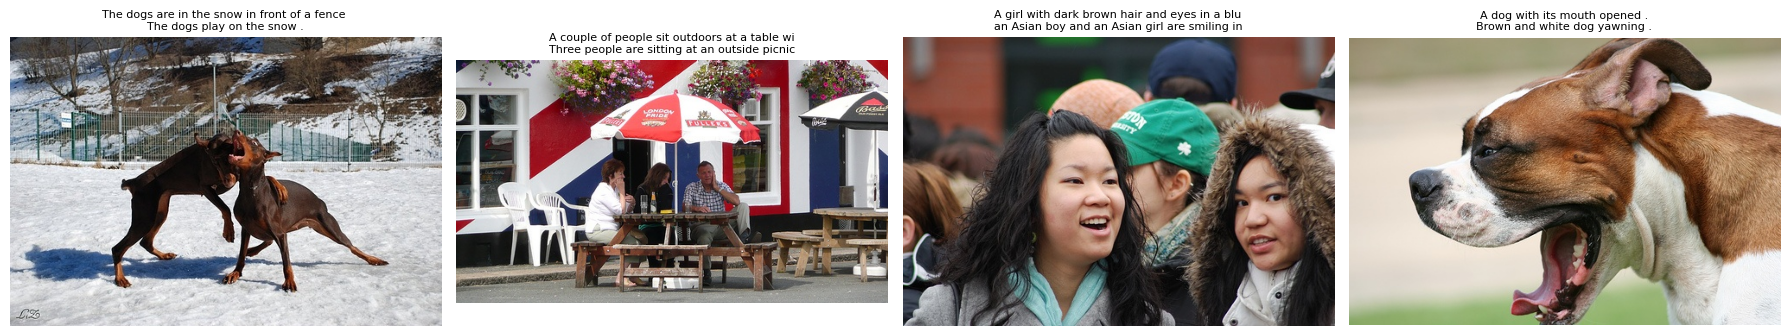

In [6]:
# Aperçu de quelques images et de leurs légendes humaines
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, img_id in zip(axes, IDS[:4]):
    ax.imshow(load_img(img_id)); ax.axis("off")
    ax.set_title("\n".join(r[:45] for r in REFS[img_id][:2]), fontsize=8)
plt.tight_layout(); plt.show()

## Chargement des VLMs en 16, 8 et 4 bits

La **quantification** stocke les poids du modèle avec moins de bits :

| Précision | Méthode | Mémoire des poids (≈ pour 2 B paramètres) |
|---|---|---|
| 16 bits | float16 / bfloat16 | ~4,4 Go |
| 8 bits | `bitsandbytes` LLM.int8 | ~2,5 Go |
| 4 bits | `bitsandbytes` NF4 + double quantification | ~1,5 Go |

On ne ré-entraîne pas les VLMs : on fait uniquement de **l'inférence**, comme le demande le sujet.

In [7]:
import transformers
from packaging import version
from transformers import AutoProcessor, BitsAndBytesConfig
# Nouvelles versions de transformers : argument `dtype` ; anciennes : `torch_dtype`
DTYPE_KW = {"dtype": DTYPE} if version.parse(transformers.__version__) >= version.parse("4.56") else {"torch_dtype": DTYPE}
print("transformers", transformers.__version__)
try:
    from transformers import AutoModelForImageTextToText as AutoVLM
except ImportError:
    from transformers import AutoModelForVision2Seq as AutoVLM

def quant_config(precision):
    if precision == "16bit":
        return None
    if precision == "8bit":
        return BitsAndBytesConfig(load_in_8bit=True)
    if precision == "4bit":
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                  bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
    raise ValueError(precision)

def load_vlm(name, precision):
    model_id = MODELS[name]
    # On limite la résolution vue par le modèle pour garder un nombre de tokens image raisonnable
    if "Qwen" in model_id:
        proc_kwargs = dict(min_pixels=128 * 28 * 28, max_pixels=512 * 28 * 28)
    elif "SmolVLM" in model_id:
        proc_kwargs = dict(size={"longest_edge": 2 * 384})
    else:
        proc_kwargs = {}
    try:
        processor = AutoProcessor.from_pretrained(model_id, **proc_kwargs)
    except Exception:
        processor = AutoProcessor.from_pretrained(model_id)
    model = AutoVLM.from_pretrained(model_id, device_map="cuda:0",
                                    quantization_config=quant_config(precision), **DTYPE_KW)
    model.eval()
    return model, processor

def unload(*objs):
    for o in objs:
        del o
    gc.collect(); torch.cuda.empty_cache()

@torch.inference_mode()
def vlm_generate(model, processor, image, prompt, max_new_tokens=MAX_NEW_TOKENS):
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=text, images=[image], return_tensors="pt")
    inputs = {k: (v.to(model.device, DTYPE) if torch.is_floating_point(v) else v.to(model.device))
              for k, v in inputs.items()}
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new_tokens = out[:, inputs["input_ids"].shape[1]:]
    return processor.batch_decode(new_tokens, skip_special_tokens=True)[0].strip()

def clean_caption(text):
    # Garde la première ligne / phrase et retire un éventuel préfixe « Assistant: ».
    text = re.sub(r"^\s*(assistant\s*:)\s*", "", text.strip(), flags=re.I)
    text = text.split("\n")[0].strip()
    m = re.match(r"(.{15,}?[.!?])(\s|$)", text)
    return (m.group(1) if m else text).strip()

transformers 5.22.2


In [8]:
# Test rapide : un modèle en 4 bits sur une image
m, p = load_vlm("SmolVLM-2B", "4bit")
img = load_img(IDS[0])
print("VLM  :", clean_caption(vlm_generate(m, p, img, CAPTION_PROMPT)))
print("Réf. :", REFS[IDS[0]][0])
unload(m, p); del m, p; gc.collect(); torch.cuda.empty_cache()

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.45k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.48k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

VLM  : Two dogs are fighting in the snow.
Réf. : The dogs are in the snow in front of a fence .


### Premier test des trois précisions

In [9]:
# Premier essai des 3 précisions sur le même modèle et les mêmes 3 images (résultats sauvegardés pour GitHub)
test_rows = []
for prec in PRECISIONS:
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    m, p = load_vlm("SmolVLM-2B", prec)
    mem = m.get_memory_footprint() / 1e9
    print(f"=== SmolVLM-2B {prec} — poids : {mem:.2f} Go")
    for img_id in IDS[:3]:
        t = time.time()
        cap = clean_caption(vlm_generate(m, p, load_img(img_id), CAPTION_PROMPT))
        dt = time.time() - t
        print(f"  {img_id} ({dt:.1f} s) : {cap}")
        test_rows.append({"precision": prec, "image": img_id, "poids_Go": round(mem, 2),
                          "temps_s": round(dt, 2), "legende": cap, "reference": REFS[img_id][0]})
    unload(m, p); del m, p; gc.collect(); torch.cuda.empty_cache()

test_df = pd.DataFrame(test_rows)
test_df.to_csv(RES_DIR / "test_precisions.csv", index=False)
shutil.copy(META_PATH, RES_DIR / "subset.json")      # liste des images choisies + légendes humaines
test_df

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

=== SmolVLM-2B 16bit — poids : 4.49 Go
  img_0000 (0.8 s) : Two dogs are fighting in the snow.
  img_0003 (0.8 s) : People sitting at a picnic table under a red and white umbrella.
  img_0006 (0.6 s) : Group of people with one woman smiling.


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

=== SmolVLM-2B 8bit — poids : 2.45 Go
  img_0000 (1.9 s) : Two dogs are fighting in the snow.
  img_0003 (2.0 s) : People sitting at a picnic table under a red and white umbrella.
  img_0006 (1.3 s) : Group of people with one woman smiling.


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

=== SmolVLM-2B 4bit — poids : 1.43 Go
  img_0000 (0.9 s) : Two dogs are fighting in the snow.
  img_0003 (1.1 s) : People sitting at a picnic table under a red and white umbrella.
  img_0006 (0.8 s) : Group of people with one smiling.


,precision,image,poids_Go,temps_s,legende,reference
0,16bit,img_0000,4.49,0.76,Two dogs are fighting in the snow.,The dogs are in the snow in front of a fence .
1,16bit,img_0003,4.49,0.83,People sitting at a picnic table under a red a...,A couple of people sit outdoors at a table wit...
2,16bit,img_0006,4.49,0.61,Group of people with one woman smiling.,A girl with dark brown hair and eyes in a blue...
3,8bit,img_0000,2.45,1.86,Two dogs are fighting in the snow.,The dogs are in the snow in front of a fence .
4,8bit,img_0003,2.45,1.99,People sitting at a picnic table under a red a...,A couple of people sit outdoors at a table wit...
5,8bit,img_0006,2.45,1.34,Group of people with one woman smiling.,A girl with dark brown hair and eyes in a blue...
6,4bit,img_0000,1.43,0.92,Two dogs are fighting in the snow.,The dogs are in the snow in front of a fence .
7,4bit,img_0003,1.43,1.07,People sitting at a picnic table under a red a...,A couple of people sit outdoors at a table wit...
8,4bit,img_0006,1.43,0.78,Group of people with one smiling.,A girl with dark brown hair and eyes in a blue...


## Mettre à jour GitHub
1. *Fichier → Enregistrer une copie dans GitHub* : dépôt `wafae36/projet7-vlm-compacts`, branche **`wafae`**, chemin **`notebooks/01_donnees_generation.ipynb`**, message `Préparation des données et premier test 16/8/4 bits`.
2. Exécute la cellule ci-dessous et décompresse le zip téléchargé.
3. Sur GitHub, branche `wafae`, dossier `results/` : *Add file → Upload files*, ajoute `test_precisions.csv` et `subset.json`.
4. Ouvre une pull request de `wafae` vers `main`.

In [10]:
# Rassemble les résultats légers (CSV, JSON, PNG) à pousser — jamais les images ni les modèles
import zipfile, glob
zip_path = ROOT / "results_wafae.zip"
files = []
for pat in ['test_precisions.csv', 'subset.json']:
    files += glob.glob(str(RES_DIR / pat))
with zipfile.ZipFile(zip_path, "w") as z:
    for f in sorted(set(files)):
        z.write(f, arcname=Path(f).name)
print(len(set(files)), "fichiers →", zip_path)
try:
    from google.colab import files as colab_files
    colab_files.download(str(zip_path))
except Exception:
    pass

2 fichiers → /content/drive/MyDrive/projet7_vlm/results_wafae.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>